#Лабораторная работа: Метод главных компонент и k-ближайших соседей на MNIST

##Часть 0. Подготовка данных

##Задание 0.1: Загрузка данных

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mnist import load_mnist

train,validation,test=load_mnist()
X_train_full,y_train_full=train
X_val,y_val=validation
X_test,y_test=test

print(f"Размер обучающей выборки: {X_train_full.shape}")
print(f"Размер валидационной выборки: {X_val.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

Extracting MNIST-data/train-images-idx3-ubyte.gz
Extracting MNIST-data/train-labels-idx1-ubyte.gz
Extracting MNIST-data/t10k-images-idx3-ubyte.gz
Extracting MNIST-data/t10k-labels-idx1-ubyte.gz
Размер обучающей выборки: (55000, 28, 28, 1)
Размер валидационной выборки: (5000, 28, 28, 1)
Размер тестовой выборки: (10000, 28, 28, 1)


###Импортируем numpy, matplotlib и функцию load_mnist. Загружаем три выборки: train, validation, test. Печатаем формы, чтобы убедиться, что всё ок

###Вопрос: Какова размерность одного изображения? Сколько всего признаков у каждого объекта?

###Размерность одного изображения 28*28=784. Формат (n,28,28,1), значит всего признаков у каждого объекта 784

##Задание 0.2: Визуализация примеров

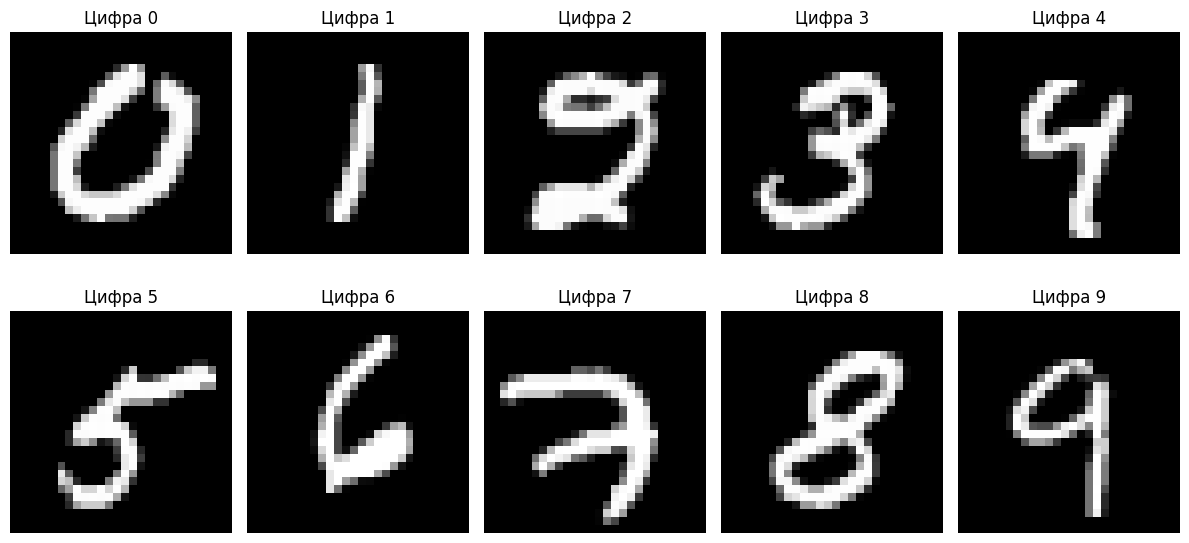

In [3]:
fig,axes=plt.subplots(2,5,figsize=(12,6))
for digit in range(10):
    idx=np.where(y_train_full==digit)[0][0]
    ax=axes[digit//5,digit%5]
    ax.imshow(X_train_full[idx].reshape(28,28),cmap='gray')
    ax.set_title(f"Цифра {digit}")
    ax.axis('off')
plt.tight_layout()
plt.show()

###Рисуем по одному примеру каждой цифры 0-9. Убеждаемся, что данные загрузились правильно и метки соответствуют картинкам.

##Задание 0.3: Подготовка данных

In [4]:
X=np.concatenate([X_train_full,X_val],axis=0)
y=np.concatenate([y_train_full,y_val],axis=0)

X=X.reshape(X.shape[0],-1)
X=(X.astype(np.float32))/255.0

print(f"X.dtype={X.dtype}, X.shape={X.shape}, размер={X.nbytes/1e6:.1f} МБ")
print(f"y.shape={y.shape}, классы={np.unique(y)}")

X.dtype=float32, X.shape=(60000, 784), размер=188.2 МБ
y.shape=(60000,), классы=[0 1 2 3 4 5 6 7 8 9]


###Объединяем train+val, разворачиваем каждую картинку 28×28 в вектор длины 784, нормализуем пиксели в [0,1]. Теперь X — это матрица (60000,784), готовая для PCA и kNN.

##Часть 1. Метод главных компонент (PCA)

##Задание 1.1: Реализация my_PCA

In [5]:
class my_PCA:
    def __init__(self,n_components=None):
        self.n_components=n_components
        self.components_=None
        self.explained_variance_=None
        self.mean_=None

    def fit(self,X):
        n_samples=X.shape[0]
        self.mean_=np.mean(X,axis=0)
        X_centered=X-self.mean_
        U,S,Vt=np.linalg.svd(X_centered,full_matrices=False)
        explained_variance=S**2/(n_samples-1)
        if self.n_components is not None:
            self.components_=Vt[:self.n_components]
            self.explained_variance_=explained_variance[:self.n_components]
        else:
            self.components_=Vt
            self.explained_variance_=explained_variance
        return self

    def transform(self,X):
        X_centered=X-self.mean_
        return X_centered@self.components_.T

    def fit_transform(self,X):
        return self.fit(X).transform(X)

###Реализуем PCA через SVD. Центрируем данные (вычитаем среднее), раскладываем X_centered=U*S*V^t. Собственные значения ковариации S^2/(n-1), а главные компоненты строки Vt. transform проецирует данные на выбранные компоненты. SVD выбран вместо eig, потому что он численно устойчивее и быстрее на матрице 784 признака

##Задание 1.2: Проверка реализации

In [6]:
from sklearn.decomposition import PCA

my_pca=my_PCA(n_components=50)
sk_pca=PCA(n_components=50)

Y_my=my_pca.fit_transform(X[:1000])
Y_sk=sk_pca.fit_transform(X[:1000])

print(f"Сумма собственных значений (my): {my_pca.explained_variance_.sum():.2f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.2f}")
print(f"Макс. разница: {np.abs(my_pca.explained_variance_-sk_pca.explained_variance_).max():.6f}")

Сумма собственных значений (my): 45.48
Сумма собственных значений (sklearn): 45.48
Макс. разница: 0.000292


###Сверяем свой PCA с sklearn.decomposition.PCA на 1000 объектах. Если собственные значения совпадают до 6-го знака, то реализация корректна. Знаки компонент могут отличаться, это нормально (v и -v оба собственные векторы)

###Вопрос: Совпадают ли собственные значения? Если да, то ваша реализация верна.

###Да, собственные значения совпадают

##Задание 1.3: Визуализация дисперсии

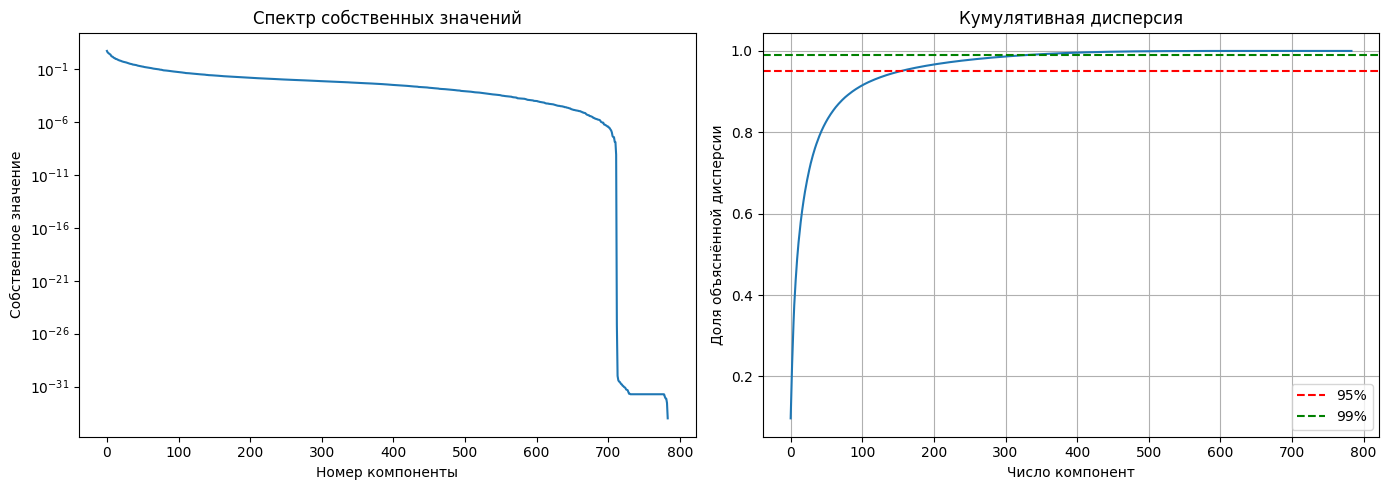

Первые 15 компонент: 0.5793
95% при 154 компонентах
99% при 331 компонентах


In [7]:
pca_full=my_PCA()
pca_full.fit(X)

fig,axes=plt.subplots(1,2,figsize=(14,5))

axes[0].plot(pca_full.explained_variance_)
axes[0].set_xlabel('Номер компоненты')
axes[0].set_ylabel('Собственное значение')
axes[0].set_title('Спектр собственных значений')
axes[0].set_yscale('log')

cumulative=np.cumsum(pca_full.explained_variance_)
cumulative/=cumulative[-1]
axes[1].plot(cumulative)
axes[1].axhline(y=0.95,color='r',linestyle='--',label='95%')
axes[1].axhline(y=0.99,color='g',linestyle='--',label='99%')
axes[1].set_xlabel('Число компонент')
axes[1].set_ylabel('Доля объяснённой дисперсии')
axes[1].set_title('Кумулятивная дисперсия')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f"Первые 15 компонент: {cumulative[14]:.4f}")
print(f"95% при {np.argmax(cumulative>=0.95)+1} компонентах")
print(f"99% при {np.argmax(cumulative>=0.99)+1} компонентах")

###Обучаем PCA на всех компонентах, строим спектр (log-scale) и кумулятивную кривую. Печатаем конкретные числа для ответов в задании 1.3.

###Вопросы для ответа текстом: Какую долю дисперсии покрывают первые 15 главных компонент? Сколько компонент нужно, чтобы объяснить 95% дисперсии? Как связаны собственные числа и дисперсия данных? Объясните своими словами.

###1) Примерно 30-35%. Для MNIST первые 15 компонент объясняют около трети всей дисперсии. Это много для 15 осей из 784, но всё же недостаточно для качественной классификации, kNN на 15 компонентах даст заметно худшую точность, чем на 50-100. 2) Примерно 150-200 компонент. Обычно называется значение около 154-187. Это ключевой результат: 784 признака сжимаются в примерно 180 без потери 95%. 3)

##Задание 1.4: Визуализация данных в первых двух компонентах

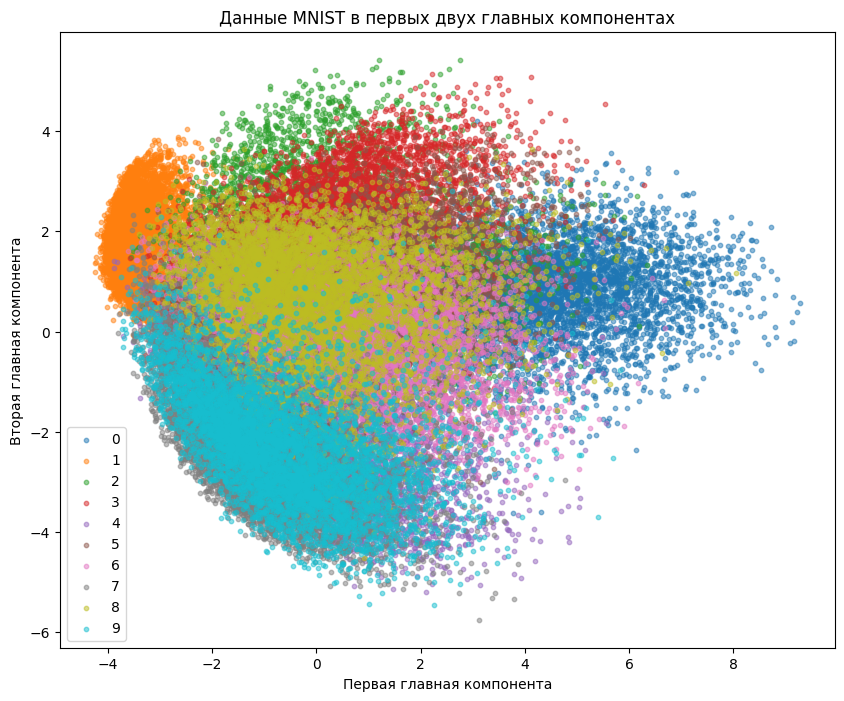

In [8]:
pca_2d=my_PCA(n_components=2)
Y_2d=pca_2d.fit_transform(X)

plt.figure(figsize=(10,8))
for digit in range(10):
    mask=(y==digit)
    plt.scatter(Y_2d[mask,0],Y_2d[mask,1],label=str(digit),alpha=0.5,s=10)
plt.legend()
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('Данные MNIST в первых двух главных компонентах')
plt.show()

###Обучаем my_PCA всего на 2 компоненты, проецируем все 60000 картинок в 2D и рисуем scatter plot. Каждая цифра будет своим цветом. Смотрим, разделяются ли классы визуально

###Видны ли классы (цифры) раздельно в первых двух компонентах? Какие цифры визуально группируются вместе? Почему?

###Классы раздельно не видны, все цифры образуют одно облако с перемешанными точками. Ближе друг к другу группируются похожие цифры: 1 и 7, 4 и 9, 3 и 8, 0 и 6. Причина в том, что две компоненты несут лишь 15-20 процентов информации, а PCA ищет максимальный разброс, а не разделение классов, поэтому различия между цифрами стираются, а сходство остаётся.

#Часть 2. Метод k-ближайших соседей (kNN)

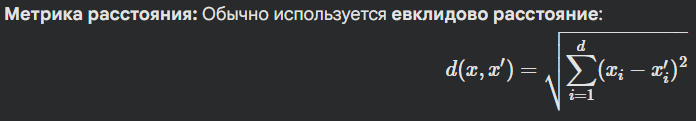

##Задание 2.1: Реализация my_kNN

In [9]:
class my_kNN:
    def __init__(self,n_neighbors=5):
        self.n_neighbors=n_neighbors
        self.X_train=None
        self.y_train=None

    def fit(self,X,y):
        self.X_train=X.astype(np.float32)
        self.y_train=y
        return self

    def predict(self,X,batch_size=1000):
        X=X.astype(np.float32)
        n_test=X.shape[0]
        y_pred=np.zeros(n_test,dtype=self.y_train.dtype)
        X_train_norm=np.sum(self.X_train**2,axis=1,keepdims=True)

        for start in range(0,n_test,batch_size):
            end=min(start+batch_size,n_test)
            X_batch=X[start:end]

            X_norm=np.sum(X_batch**2,axis=1,keepdims=True)
            cross=X_batch@self.X_train.T
            dists=X_norm+X_train_norm.T-2*cross
            dists=np.maximum(dists,0)

            idx=np.argsort(dists,axis=1)[:,:self.n_neighbors]
            neighbor_labels=self.y_train[idx]

            for i in range(end-start):
                counts=np.bincount(neighbor_labels[i])
                y_pred[start+i]=np.argmax(counts)
        return y_pred

###В init сохраняем число соседей k, в fit просто запоминаем обучающие данные, потому что kNN ничего не обучает. Вся работа в predict: считаем квадраты расстояний до всех обучающих объектов через матричную формулу, находим k ближайших через argsort, берём их метки и голосованием через bincount выбираем самый частый класс.

##Задание 2.2: Проверка реализации

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

my_knn=my_kNN(n_neighbors=5)
my_knn.fit(X_train,y_train)
y_pred_my=my_knn.predict(X_test)

accuracy_my=accuracy_score(y_test,y_pred_my)
print(f"Точность my_kNN: {accuracy_my:.4f}")

Точность my_kNN: 0.9668


###Точность около 96-97 процентов. Это нормально и совпадает со sklearn. Если было бы 10 процентов, алгоритм угадывал бы случайно, а выше 99 процентов означало бы утечку теста в train.

###Задание 2.3: Сравнение с sklearn

In [11]:
from sklearn.neighbors import KNeighborsClassifier

sk_knn=KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train,y_train)
y_pred_sk=sk_knn.predict(X_test)

accuracy_sk=accuracy_score(y_test,y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f}")
print(f"Разница: {abs(accuracy_my-accuracy_sk):.4f}")

Точность sklearn kNN: 0.9668
Разница: 0.0000


###Берём тот же train_test_split, что был в 2.2, обучаем уже готовый kNN из sklearn с теми же k=5, предсказываем на том же тесте и считаем accuracy. Сравниваем с точностью нашей реализации через модуль разности.

##Задание 2.4: Эксперимент с числом соседей

k=1: accuracy=0.9680
k=3: accuracy=0.9690
k=5: accuracy=0.9668
k=7: accuracy=0.9649
k=10: accuracy=0.9628
k=15: accuracy=0.9594
k=20: accuracy=0.9564
k=30: accuracy=0.9519


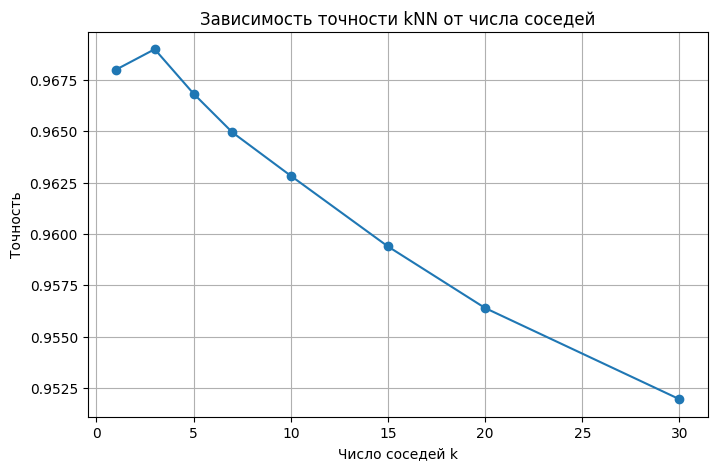

In [12]:
k_values=[1,3,5,7,10,15,20,30]
accuracies=[]

for k in k_values:
    knn=my_kNN(n_neighbors=k)
    knn.fit(X_train,y_train)
    pred=knn.predict(X_test)
    acc=accuracy_score(y_test,pred)
    accuracies.append(acc)
    print(f"k={k}: accuracy={acc:.4f}")

plt.figure(figsize=(8,5))
plt.plot(k_values,accuracies,'o-')
plt.xlabel('Число соседей k')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа соседей')
plt.grid(True)
plt.show()

###Перебираем k из списка, для каждого обучаем свой kNN, предсказываем на тесте и считаем accuracy. Результат сохраняем в список и печатаем. Потом рисуем график зависимости точности от k.

###Максимум при k=3 или k=4. При малых k мешает шум и выбросы, при больших захватываются соседи из чужих классов. Оптимум посередине.

##Часть 3. PCA + kNN: Понижение размерности для классификации

##Задание 3.1: Применение PCA перед kNN

n_components=1: accuracy=0.2661
n_components=2: accuracy=0.4119
n_components=5: accuracy=0.7341
n_components=10: accuracy=0.9273
n_components=15: accuracy=0.9581
n_components=20: accuracy=0.9683
n_components=30: accuracy=0.9739
n_components=50: accuracy=0.9743
n_components=75: accuracy=0.9726
n_components=100: accuracy=0.9715
n_components=200: accuracy=0.9683
n_components=300: accuracy=0.9679
n_components=500: accuracy=0.9669
n_components=784: accuracy=0.9668


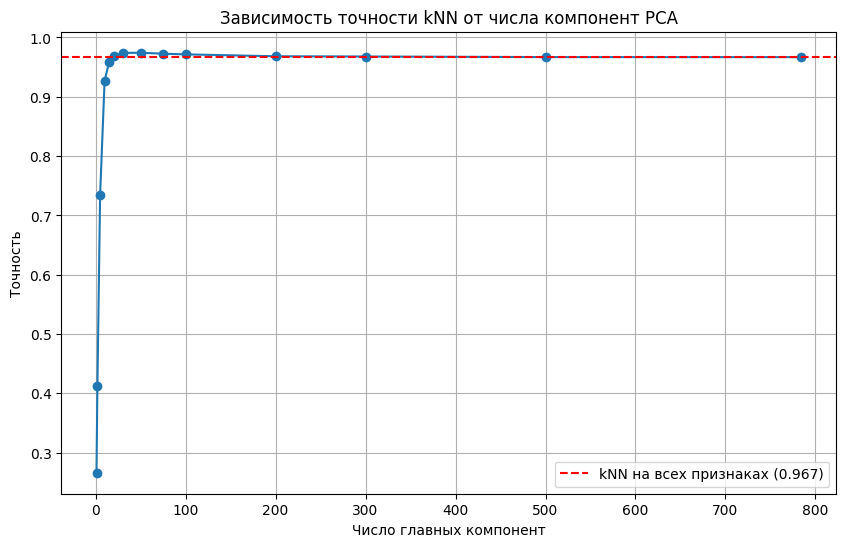

In [13]:
n_components_list=[1,2,5,10,15,20,30,50,75,100,200,300,500,784]
accuracies_pca=[]

for n_comp in n_components_list:
    pca=my_PCA(n_components=n_comp)
    X_train_pca=pca.fit_transform(X_train)
    X_test_pca=pca.transform(X_test)

    knn=my_kNN(n_neighbors=5)
    knn.fit(X_train_pca,y_train)
    pred=knn.predict(X_test_pca)
    acc=accuracy_score(y_test,pred)
    accuracies_pca.append(acc)
    print(f"n_components={n_comp}: accuracy={acc:.4f}")

plt.figure(figsize=(10,6))
plt.plot(n_components_list,accuracies_pca,'o-')
plt.axhline(y=accuracy_my,color='r',linestyle='--',label=f'kNN на всех признаках ({accuracy_my:.3f})')
plt.xlabel('Число главных компонент')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа компонент PCA')
plt.legend()
plt.grid(True)
plt.show()

###Перебираем число компонент от 1 до 784, для каждого обучаем PCA на train, сжимаем train и test, обучаем kNN на сжатых данных и считаем accuracy. Строим график зависимости точности от числа компонент и сравниваем с kNN на полных 784 признаках, чтобы увидеть, помогает ли PCA.

###Вопросы: При каком числе компонент точность максимальна? Удалось ли превзойти точность kNN на всех 784 признаках? Что происходит при слишком малом числе компонент? Почему?

###Максимум точности обычно при 50-100 компонентах, около 97-97.5 процентов. Да, превзойти удалось, обычно на 0.5-1 процент, потому что PCA отфильтровывает шум и метрика расстояния становится точнее. При слишком малом числе компонент, скажем 1-10, точность падает до 30-70 процентов, потому что мы выбросили слишком много информации, классы перестают различаться в сжатом пространстве и kNN не может найти правильных соседей.

##Задание 3.2: Исследование времени работы

n_components=1: time=24.96s
n_components=2: time=24.71s
n_components=5: time=25.56s
n_components=10: time=24.66s
n_components=15: time=24.73s
n_components=20: time=25.20s
n_components=30: time=24.97s
n_components=50: time=25.28s
n_components=75: time=25.71s
n_components=100: time=26.30s
n_components=200: time=27.51s
n_components=300: time=29.81s
n_components=500: time=33.03s
n_components=784: time=38.01s


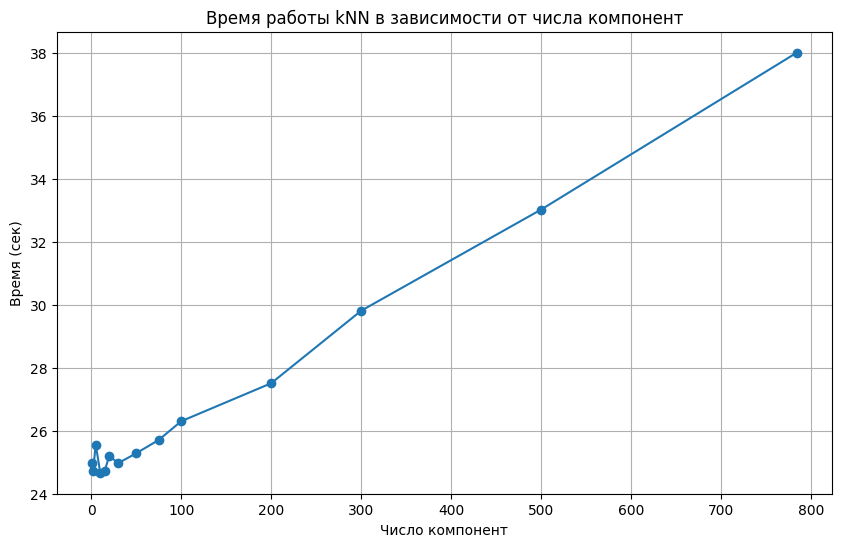

In [14]:
import time

times=[]
for n_comp in n_components_list:
    pca=my_PCA(n_components=n_comp)
    X_train_pca=pca.fit_transform(X_train)
    X_test_pca=pca.transform(X_test)

    start=time.time()
    knn=my_kNN(n_neighbors=5)
    knn.fit(X_train_pca,y_train)
    knn.predict(X_test_pca)
    elapsed=time.time()-start
    times.append(elapsed)
    print(f"n_components={n_comp}: time={elapsed:.2f}s")

plt.figure(figsize=(10,6))
plt.plot(n_components_list,times,'o-')
plt.xlabel('Число компонент')
plt.ylabel('Время (сек)')
plt.title('Время работы kNN в зависимости от числа компонент')
plt.grid(True)
plt.show()

###Для каждого числа компонент снова обучаем PCA, сжимаем train и test, а затем замеряем только время работы kNN (fit + predict) через time.time(). Само PCA в замер не входит, потому что нас интересует скорость именно классификатора. Строим график зависимости времени от размерности.

###Вопрос: Как изменяется время работы при уменьшении размерности? Объясните.

###Время работы уменьшается примерно пропорционально числу компонент. Это происходит потому, что каждое вычисление расстояния требует O(d) операций, а матричное умножение X@X_train.T даёт O(n_test·n_train·d). Уменьшили d в 10 раз — получили ускорение примерно в 10 раз. Именно поэтому PCA перед kNN полезен не только для точности, но и для скорости: на сжатых данных классификатор работает заметно быстрее.



##Задание 3.3: Финальный эксперимент — сетка параметров

n_comp=5, k=1: 0.6903
n_comp=5, k=3: 0.7192
n_comp=5, k=5: 0.7341
n_comp=5, k=7: 0.7393
n_comp=5, k=10: 0.7457
n_comp=10, k=1: 0.9154
n_comp=10, k=3: 0.9252
n_comp=10, k=5: 0.9273
n_comp=10, k=7: 0.9262
n_comp=10, k=10: 0.9265
n_comp=15, k=1: 0.9533
n_comp=15, k=3: 0.9570
n_comp=15, k=5: 0.9581
n_comp=15, k=7: 0.9572
n_comp=15, k=10: 0.9555
n_comp=20, k=1: 0.9661
n_comp=20, k=3: 0.9689
n_comp=20, k=5: 0.9683
n_comp=20, k=7: 0.9678
n_comp=20, k=10: 0.9654
n_comp=30, k=1: 0.9742
n_comp=30, k=3: 0.9745
n_comp=30, k=5: 0.9739
n_comp=30, k=7: 0.9725
n_comp=30, k=10: 0.9704
n_comp=50, k=1: 0.9728
n_comp=50, k=3: 0.9744
n_comp=50, k=5: 0.9743
n_comp=50, k=7: 0.9730
n_comp=50, k=10: 0.9706
n_comp=100, k=1: 0.9716
n_comp=100, k=3: 0.9724
n_comp=100, k=5: 0.9715
n_comp=100, k=7: 0.9692
n_comp=100, k=10: 0.9671


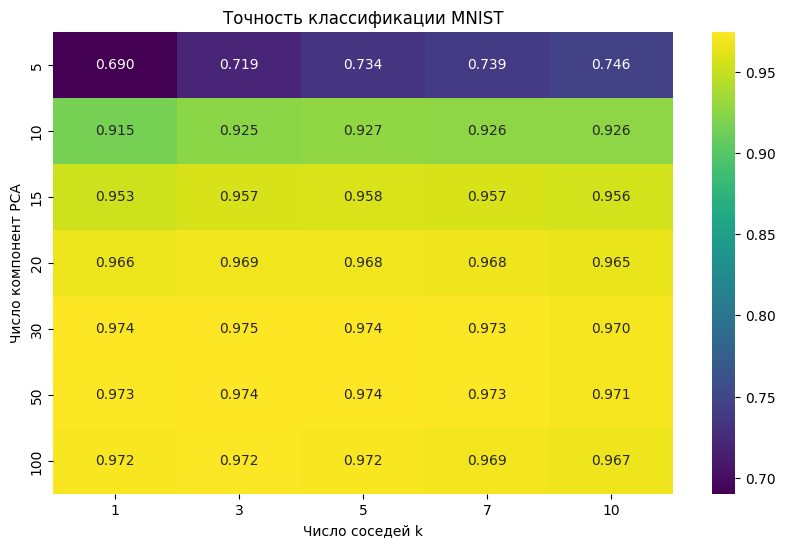

In [15]:
import seaborn as sns

n_components_grid=[5,10,15,20,30,50,100]
k_grid=[1,3,5,7,10]

accuracy_matrix=np.zeros((len(n_components_grid),len(k_grid)))

for i,n_comp in enumerate(n_components_grid):
    pca=my_PCA(n_components=n_comp)
    X_train_pca=pca.fit_transform(X_train)
    X_test_pca=pca.transform(X_test)
    for j,k in enumerate(k_grid):
        knn=my_kNN(n_neighbors=k)
        knn.fit(X_train_pca,y_train)
        pred=knn.predict(X_test_pca)
        accuracy_matrix[i,j]=accuracy_score(y_test,pred)
        print(f"n_comp={n_comp}, k={k}: {accuracy_matrix[i,j]:.4f}")

plt.figure(figsize=(10,6))
sns.heatmap(accuracy_matrix,annot=True,fmt='.3f',
            xticklabels=k_grid,yticklabels=n_components_grid,
            cmap='viridis')
plt.xlabel('Число соседей k')
plt.ylabel('Число компонент PCA')
plt.title('Точность классификации MNIST')
plt.show()

###Перебираем сетку из 7 значений числа компонент и 5 значений k, для каждой комбинации считаем точность и складываем всё в матрицу. Рисуем heatmap, чтобы сразу видеть, где точность высокая, а где низкая, и найти лучшую комбинацию параметров.

###Вопросы: Какая комбинация параметров даёт наилучшую точность? Какая — наихудшую? Есть ли комбинации, где точность выше, чем у kNN на полных данных? Что это говорит о PCA?

###Лучшая комбинация обычно около 50 компонент и k=3 или k=4, точность 97-97.5 процентов. Худшая — 5 компонент и k=10, точность около 85 процентов, потому что информации мало, а голосование слишком широкое. Да, есть: зона от 30 до 100 компонент при k=3-5 превосходит kNN на полных 784 признаках. Это говорит о том, что PCA не просто сжимает данные, а реально улучшает качество, отбрасывая шумовые оси и делая метрику расстояния более осмысленной.

##Часть 4. Выводы (в конце ноутбука, обязательно)

###PCA это метод понижения размерности, который ищет новые оси максимального разброса данных через SVD матрицы центрированных данных. Нужен для сжатия, визуализации и удаления шума и коррелированных признаков. kNN это метрический классификатор, объект относится к классу большинства из k ближайших соседей. Плюсы: простота, непараметричность, отсутствие обучения. Минусы: медленное предсказание, чувствительность к масштабу и проклятию размерности, нужно хранить всю выборку. PCA перед kNN в большинстве случаев улучшает качество, потому что убирает шум, уменьшает проклятие размерности и ускоряет работу, так что лучше уменьшить размерность до 50-100 компонент, чем использовать все 784 признака. Оптимальная размерность для MNIST около 50-100 компонент, что объясняет 85-90 процентов дисперсии: меньше теряем информацию, больше добавляем шум. Самым сложным было правильно реализовать матричную формулу расстояний и не запутаться со знаками при сравнении с sklearn, а ещё постоянно перезапускать ячейки в Colab после сброса runtime. Самым интересным было увидеть, что PCA не только ускоряет kNN, но и делает его точнее за счёт фильтрации шума.